# 03 · Prioritize unusual trade observations

**Question: with the same number of review slots, do a simple rule and Isolation Forest select different observations?**

One review slot means inspecting one monthly trade aggregate, which may contain many transactions. A queue is an ordered list of these observations.

**There are no verified fraud outcomes (“labels”). I can compare priorities and workload, not fraud detection accuracy.** An unusual observation is a reason to investigate, not evidence of fraud.

## 1. Compare each route with its own history

I use value, mass and EUR/kg from the preceding 12 calendar months, requiring nine positive, unflagged observations per measure. Comparing a route with itself avoids treating every large flow as unusual simply because it is large.

The deviation is `(log(current) − historical median) / max(1.4826 × MAD, 0.10)`:

- Logs express changes proportionally. The historical median is the middle log value; MAD is the median distance from it, a measure of usual variation.
- The factor 1.4826 puts MAD on a conventional statistical scale. The minimum denominator of 0.10 prevents an almost constant history from making a tiny change look enormous.
- Positive deviations are above the historical middle; negative ones are below. The rule uses the largest absolute deviation across the three measures. A score of 4 is an illustrative cutoff, not four times the EUR value or a fraud probability.

**The current observation never enters its own reference. Value, mass and EUR/kg are related, so three unusual measures are not three independent confirmations.** The rule does not remove seasonal patterns; I check the same month in earlier years when reviewing cases.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

from moto_study.decoding import GRAIN, ROUTE
from moto_study.io import load_prepared, project_root
from moto_study.plots import set_style
from moto_study.risk import (
    compare_review_queues,
    eligibility_reasons,
    fit_forest,
    historical_features,
    threshold_sensitivity,
)

ROOT = project_root()
set_style()
trade = load_prepared(ROOT)
features = historical_features(trade, window=12, min_history=9, scale_floor=0.10)
display(eligibility_reasons(features))
print(f"Eligible: {features.eligible.sum():,}/{len(features):,} observations.")

,reason,observations
0,eligible,46100
1,insufficient historical reference,31270
2,current missing/nonpositive measure,3282


Eligible: 46,100/80,652 observations.


**Only 46,100/80,652 rows can be scored: 31,270 lack enough history and 3,282 have nonpositive current measurements. Unscored does not mean low-risk.**

“Eligible” means enough usable data for this calculation. The comparison therefore favors established, regularly reported routes.

## 2. Choose an illustrative workload

Isolation Forest repeatedly splits observations at random cutoffs on the three deviations. Observations isolated in fewer steps receive higher unusualness scores. Combining 150 trees repeats this process; seed 42 makes the random choices repeatable.

**I fit the forest through 2023 and set thresholds from those training scores only.** A training quantile of 0.990 sets the cutoff at the 99th percentile: about 1% of training scores are higher. The share above that fixed cutoff can change in later years.

In [2]:
scored, forest, training_scores = fit_forest(features, cutoff="2023-12-01", seed=42)
sensitivity = threshold_sensitivity(scored, training_scores)
display(
    sensitivity.assign(flag_percent=sensitivity.flag_rate * 100)[
        ["training_quantile", "eligible_rows", "flagged_rows", "flag_percent"]
    ].round({"training_quantile": 3, "flag_percent": 2})
)
threshold = float(np.quantile(training_scores, 0.99))
later = scored.loc[scored.eligible & scored.month.between("2024-01-01", "2025-12-01")]
budget = int(later.iforest_score.gt(threshold).sum())
print(
    f"99th-percentile policy: {budget} forest alerts; simple rule at deviation ≥4: {later.rule_alert.sum()} alerts."
)

,training_quantile,eligible_rows,flagged_rows,flag_percent
0,0.975,13456,290,2.16
1,0.990,13456,127,0.94
2,0.995,13456,51,0.38


99th-percentile policy: 127 forest alerts; simple rule at deviation ≥4: 1035 alerts.


**The three cutoffs select 290, 127 or 51 later observations. They change the review workload, not the probability that a case is fraudulent.**

## 3. Compare equal-sized queues

**The forest's 127 alerts versus the rule's 1,035 alerts is an unequal comparison. I give each method 127 slots from the same 13,456 eligible observations.** This budget comes from the forest's 99th-percentile cutoff; it is an experiment, not a staffing recommendation.

Rank 1 is the highest priority. Ties are resolved using the row's identifying fields, so shuffling the input cannot change selection. “Forest only” and “rule only” refer to membership of the top-127 queues, not whether an observation passes the original alert cutoffs.

In [3]:
ranked = compare_review_queues(scored, budget)
overlap = ranked.queue_group.value_counts().reindex(
    ["both", "forest only", "rule only"], fill_value=0
)
display(overlap.rename("observations").to_frame())
assert ranked.forest_rank.le(budget).sum() == ranked.rule_rank.le(budget).sum() == budget
# Inspect the highest-ranked disagreement from each method, without claiming representativeness.
examples = pd.concat(
    [
        ranked.loc[ranked.queue_group.eq("forest only")].nsmallest(1, "forest_rank"),
        ranked.loc[ranked.queue_group.eq("rule only")].nsmallest(1, "rule_rank"),
    ]
)
display(examples[[*GRAIN, "forest_rank", "rule_rank"]].reset_index(drop=True))

,observations
queue_group,
both,99
forest only,28
rule only,28


,month,reporter,partner,product,flow,forest_rank,rule_rank
0,2024-10-01,FR,BE,87114000,1,49,183
1,2025-12-01,IT,HR,87113090,2,162,53


**99 observations are shared; each method selects 28 different cases. I inspect two disagreements to understand the priorities, not to decide which method finds more fraud.**

The examples are the highest-ranked observations in each method's exclusive group. They illustrate disagreements, rather than represent every queued case. A rank of 49 gets a slot; a rank of 183 falls outside the 127-slot budget.

## 4. Explain two disagreements

I reconstruct each deviation and compare it with recent history and the same month last year. In the tables, `prior_median` is the middle of the usable past 12 months, calculated on logs and converted back to the original unit. `deviation` is the signed score explained above.

FR–BE imports means France reporting imports from Belgium; IT–HR exports means Italy reporting exports to Croatia. Direction codes 1/2 mean imports/exports. The chart leaves missing months as gaps.

FR–BE imports · 2024-10 · 87114000


,prior_median,same_month_last_year,current,deviation
measure,,,,
value_eur,178593.80,186171.0,3214986.00,6.30
net_mass_kg,6938.97,6795.0,146556.00,9.16
unit_value_eur_per_kg,26.83,27.4,21.94,-2.01


IT–HR exports · 2025-12 · 87113090


,prior_median,same_month_last_year,current,deviation
measure,,,,
value_eur,56910.00,35142.0,10504.00,-1.01
net_mass_kg,2925.00,1757.0,105.00,-2.31
unit_value_eur_per_kg,19.68,20.0,100.04,16.26


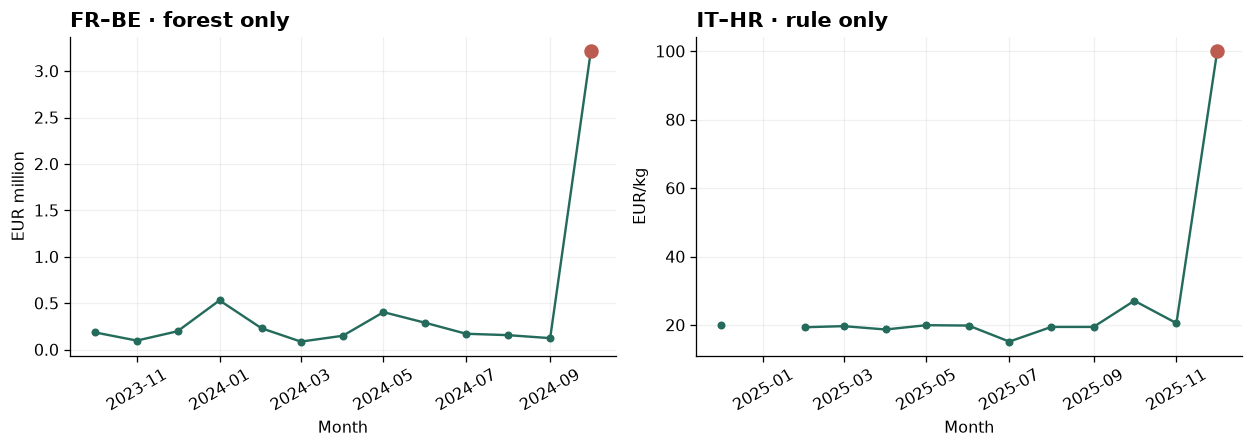

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, (_, row) in zip(axes, examples.iterrows(), strict=True):
    route = scored.loc[scored[ROUTE].eq(row[ROUTE]).all(axis=1)].set_index("month").sort_index()
    calendar = pd.date_range(row.month - pd.DateOffset(months=12), row.month, freq="MS")
    history = route.reindex(calendar)
    previous_year = history.iloc[0]
    details = []
    for measure, feature, flags in [
        ("value_eur", "value_z", ["value_eur_status"]),
        ("net_mass_kg", "mass_z", ["mass_100kg_status"]),
        ("unit_value_eur_per_kg", "unit_value_z", ["value_eur_status", "mass_100kg_status"]),
    ]:
        usable = history[measure].gt(0) & history[flags].fillna("").eq("").all(axis=1)
        prior = np.log(history[measure].where(usable).iloc[:-1]).dropna()
        assert len(prior) >= 9
        median = prior.median()
        mad = (prior - median).abs().median()
        deviation = (np.log(row[measure]) - median) / max(1.4826 * mad, 0.10)
        assert np.isclose(deviation, row[feature])
        details.append(
            {
                "measure": measure,
                "prior_median": np.exp(median),
                "same_month_last_year": previous_year[measure],
                "current": row[measure],
                "deviation": deviation,
            }
        )
    direction = "imports" if row.flow == "1" else "exports"
    label = f"{row.reporter}–{row.partner} {direction} · {row.month:%Y-%m} · {row['product']}"
    print(label)
    display(pd.DataFrame(details).set_index("measure").round(2))
    measure = "value_eur" if row.queue_group == "forest only" else "unit_value_eur_per_kg"
    scale = 1e6 if measure == "value_eur" else 1
    ax.plot(history.index, history[measure] / scale, marker="o", markersize=4)
    ax.scatter([row.month], [row[measure] / scale], color="#bc5c50", s=65, zorder=3)
    ax.set(
        title=f"{row.reporter}–{row.partner} · {row.queue_group}",
        ylabel="EUR million" if scale == 1e6 else "EUR/kg",
        xlabel="Month",
    )
    ax.tick_params(axis="x", rotation=30)
fig.tight_layout()
plt.show()

- **Forest-only: France–Belgium imports, October 2024. Value and mass rise together, while EUR/kg stays near its recent range. Forest rank: 49; rule rank: 183.** This is the >500–800 cm³ category.
- **Rule-only: Italy–Croatia exports, December 2025. EUR 10,504 / 105 kg gives EUR 100.04/kg, versus EUR 20.00/kg a year earlier. Rule rank: 53; forest rank: 162.** This is the >380–500 cm³ category.

**The forest gives higher priority to the first joint value/mass change; the rule gives higher priority to the second extreme ratio. Neither case establishes fraud.** A low weight can amplify EUR/kg. Different motorcycles within one engine category can also change the ratio.

A reviewer would check the reported weight, product mix, valuation and later revisions against supporting records. The aggregate alone cannot settle those explanations.

## Conclusion

**Equal workloads expose different priorities. I keep the simple rule as the reference; without verified review outcomes, I cannot prefer the forest.**

The export contains 155 distinct observations across the two queues, with ranks, measurements and source IDs. Shared cases appear once. Choosing a policy would require independent reviews of shared, differing and unselected observations—not just agreement between two methods. Checks for future-data leakage and source flags remain in `tests/`.

In [5]:
review = ranked.loc[ranked.queue_group.ne("neither")]
review[
    [
        *GRAIN,
        "queue_group",
        "forest_rank",
        "rule_rank",
        "value_eur",
        "net_mass_kg",
        "unit_value_eur_per_kg",
        "robust_score",
        "iforest_score",
        "reason",
        "source_id",
    ]
].to_csv(ROOT / "data/processed/review_queue.csv", index=False)
print(f"Saved {len(review)} distinct observations covering both {budget}-slot queues.")

Saved 155 distinct observations covering both 127-slot queues.
